In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *

# Test multiple mcmc (one run)

In [2]:
# Define parameters & model
N = 5000
d = 4
beta = 0.27
maxiter = 10**6
G, couplings = create_ER_graph(N, d, coupling_type='ising')
#G, couplings, N = create_lattice_graph(50, 2, model='RL_sg', periodic=True)
#G, couplings = create_complete_graph(N, model='CW')

max_degree = max(d for _, d in G.degree())
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/(d-1))
beta_dob = np.arctanh(1/d)
beta_uni, beta_SG, max_degree, beta_dob, N

(0.34657359027997264, 0.5493061443340549, 12, 0.25541281188299536, 5000)

In [3]:
# Run BC forward
nb_star_state, nb_unresolved_confs, final_step = multiple_mcmc(beta, G, couplings, sampler=F_beta_Glauber, max_iter=maxiter, n_configs=10, lazy=False, store_traj=True)

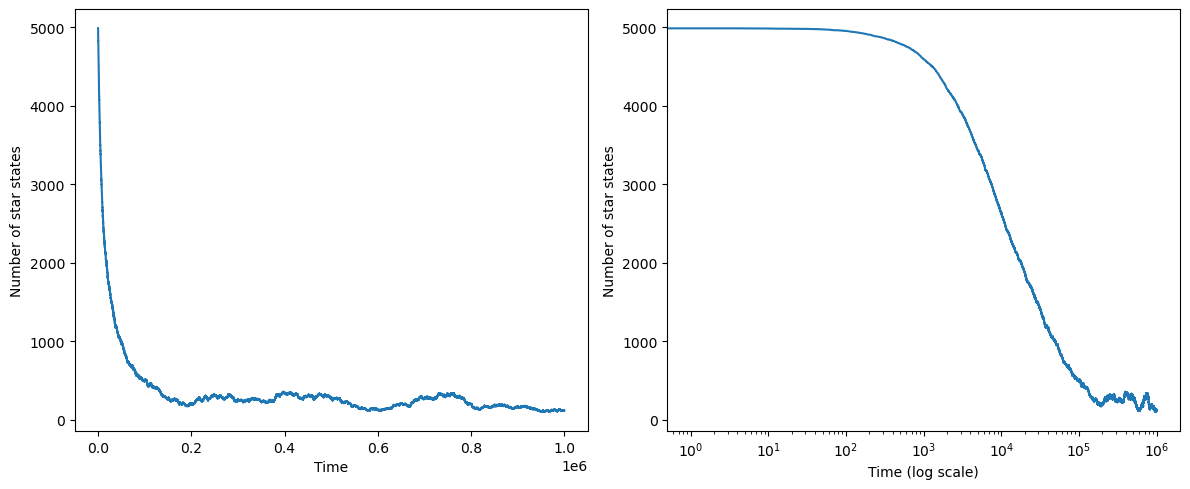

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(nb_star_state)
ax1.set_xlabel('Time')
ax1.set_ylabel('Number of star states')

ax2.plot(nb_star_state)
ax2.set_xscale('log')
ax2.set_xlabel('Time (log scale)')
ax2.set_ylabel('Number of star states')

plt.tight_layout()
plt.show()

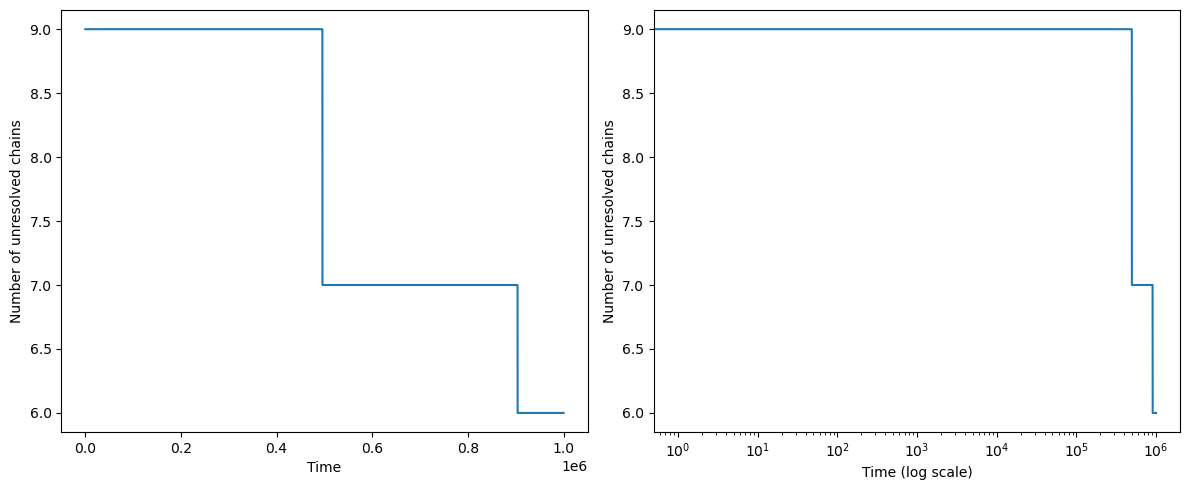

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(nb_unresolved_confs)
ax1.set_xlabel('Time')
ax1.set_ylabel('Number of unresolved chains')

ax2.plot(nb_unresolved_confs)
ax2.set_xscale('log')
ax2.set_xlabel('Time (log scale)')
ax2.set_ylabel('Number of unresolved chains')

plt.tight_layout()
plt.show()

# Coalescence times

In [6]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(0.25541281188299536, 0.5493061443340549)

In [7]:
beta = 0.25
coup_type = 'ising'
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type=coup_type)
nb_runs = 3    
nb_itermax = 10**6
N_list = [100, 500, 1000, 5000,10000]
csv_path = f"../results/tmp/coal_time_DS_ER_{coup_type}_d{d}.csv"

In [8]:
df = compute_coal_time_DS(N_list, beta, G_builder, n_runs=nb_runs, sampler=F_beta_Glauber, max_iter=nb_itermax, n_configs=100, lazy=False)

N=100
Coalescence achieved at iteration 2324.
Coalescence achieved at iteration 2766.
Coalescence achieved at iteration 744.
N=500
Coalescence achieved at iteration 42809.
Coalescence achieved at iteration 26018.
Coalescence achieved at iteration 23384.
N=1000
Coalescence achieved at iteration 83758.
Coalescence achieved at iteration 77190.
Coalescence achieved at iteration 110294.
N=5000
Coalescence achieved at iteration 541477.
Coalescence achieved at iteration 527678.
Coalescence achieved at iteration 666288.
N=10000


In [9]:
if os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    df_combined = pd.concat([df_full, df], ignore_index=True)
    df_combined.to_csv(csv_path, index=False)
else:
    df.to_csv(csv_path, index=False)

In [10]:
df = pd.read_csv(csv_path)

print(df['beta'].unique())
print(df['sampler'].unique())
print(df['lazy'].unique())
print(df['n_configs'].unique())
print(df['n_runs'].unique())
print(df['max_iter'].unique())
print(df['N'].unique())
print(len(df))  # total number of rows

df

[0.25]
['F_beta_Glauber']
[False]
[100]
[3]
[1000000]
[  100   500  1000  5000 10000]
5


,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.25,F_beta_Glauber,False,100,3,1000000,100,3,1944.666667,867.963645
1,0.25,F_beta_Glauber,False,100,3,1000000,500,3,30737.000000,8603.657246
2,0.25,F_beta_Glauber,False,100,3,1000000,1000,3,90414.000000,14310.729215
3,0.25,F_beta_Glauber,False,100,3,1000000,5000,3,578481.000000,62343.965423
4,0.25,F_beta_Glauber,False,100,3,1000000,10000,0,NaN,NaN


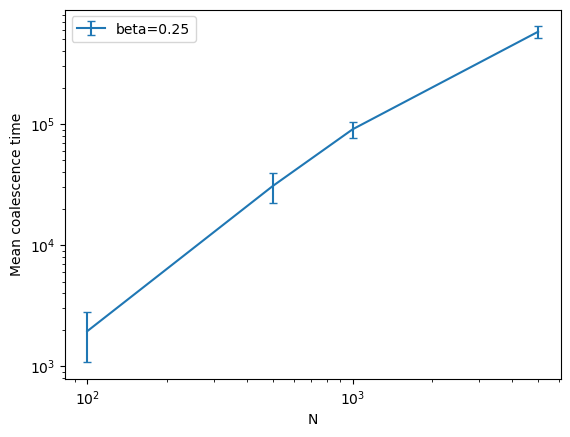

In [11]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['n_coal'] == df['n_runs'])
)
df_filtered = df[mask]

betas_to_exclude = []
for beta in df_filtered['beta'].unique():
    if beta in betas_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['beta'] == beta]
    plt.errorbar(sub_df['N'], sub_df['mean_coal_time'],
                yerr=sub_df['std_coal_time'],
                label=f'beta={beta:.2f}',
                capsize=3)

plt.xlabel('N')
plt.ylabel('Mean coalescence time')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

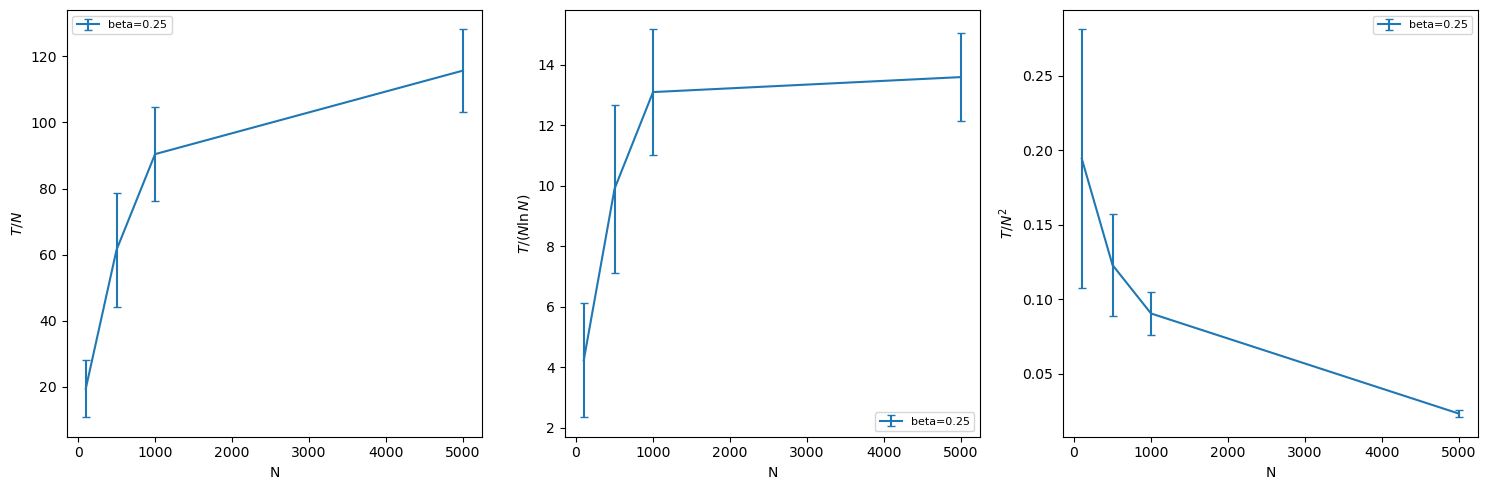

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                 lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in df_filtered['beta'].unique():
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                    label=f'beta={beta:.2f}', capsize=3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
N_to_exclude = []
for N in df['N'].unique():
    if N in N_to_exclude:
        continue    
    sub_df = df[df['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    plt.errorbar(sub_df['beta'], p,
                 yerr=[err_down, err_up],
                 label=f'N={N}', capsize=3)

plt.xlabel(r'$\beta$')
plt.ylabel('Fraction of runs coalesced')
plt.legend()
plt.show()

# Evolution star states & nb configs

In [13]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(0.25541281188299536, 0.5493061443340549)

In [14]:
N = 10000
beta_list = [0.25,0.26,0.27]
#beta_list = [0.3, 0.31, 0.32, 0.33, 0.34]
coup_type = 'ising'
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type=coup_type)
nb_runs = 5  
nb_itermax = 10**7

In [15]:
dfs = []
for beta in beta_list:
    print(f"beta={beta}")
    df_beta = compute_nb_star_DS(N, beta, G_builder, n_runs=nb_runs, sampler=F_beta_Glauber, max_iter=nb_itermax, n_configs=50, lazy=False, n_points=10000)
    dfs.append(df_beta)

df = pd.concat(dfs, ignore_index=True)

csv_path = f"../results/tmp/nb_star_DS_ER_{coup_type}_d{d}_N{N}.csv"
df.to_csv(csv_path, index=False)


beta=0.25
Coalescence achieved at iteration 1758656.
Coalescence achieved at iteration 1639539.
Coalescence achieved at iteration 1647254.
Coalescence achieved at iteration 2201018.
Coalescence achieved at iteration 1021073.
beta=0.26
Coalescence achieved at iteration 2209883.
Coalescence achieved at iteration 2084802.
Coalescence achieved at iteration 4377556.
Coalescence achieved at iteration 4361922.
Coalescence achieved at iteration 2962205.
beta=0.27


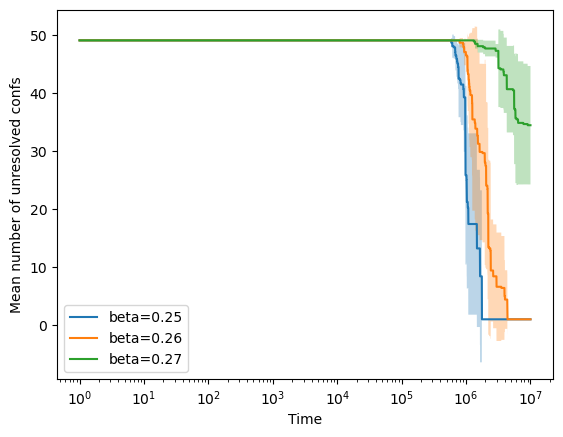

In [16]:
df = pd.read_csv(csv_path)
for beta in df['beta'].unique():
    sub_df = df[df['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_confs'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_confs'] - sub_df['std_nb_confs'],
                     sub_df['mean_nb_confs'] + sub_df['std_nb_confs'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of unresolved confs')
plt.legend()
plt.show()

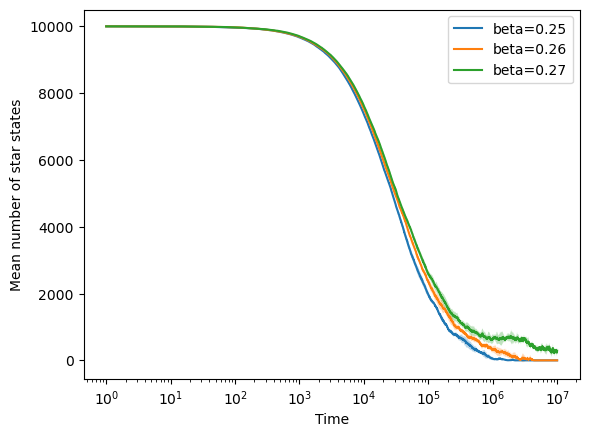

In [17]:
df = pd.read_csv(csv_path)
for beta in df['beta'].unique():
    sub_df = df[df['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_star'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                     sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of star states')
plt.legend()
plt.show()

C = 0.011, R²=0.9274


/tmp/ipykernel_5329/997020366.py:6: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)


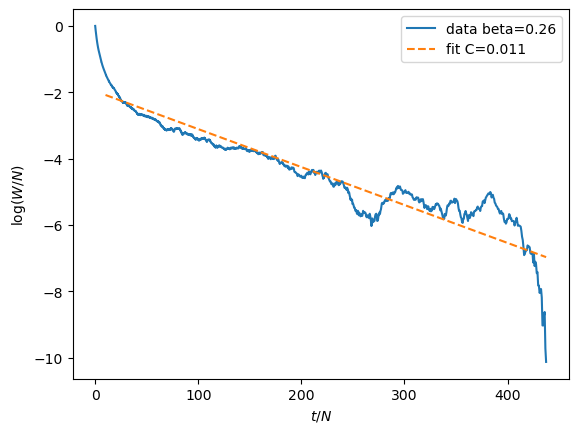

In [18]:
beta = 0.26
sub_df = df[df['beta'] == beta].sort_values('time')
N = sub_df['N'].values[0]

t_over_N = sub_df['time'].values / N
log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)

from scipy.stats import linregress

mask = (t_over_N > 10)  & (log_W_over_N > -np.inf) & np.isfinite(log_W_over_N)
slope, intercept, r, p, se = linregress(t_over_N[mask], log_W_over_N[mask])
C = -slope
print(f"C = {C:.3f}, R²={r**2:.4f}")

plt.plot(t_over_N, log_W_over_N, label=f'data beta={beta:.2f}')
plt.plot(t_over_N[mask], intercept + slope * t_over_N[mask], '--', label=f'fit C={C:.3f}')
plt.xlabel(r'$t/N$')
plt.ylabel(r'$\log(W/N)$')
plt.legend()
plt.show()

/tmp/ipykernel_5329/1273124830.py:7: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)


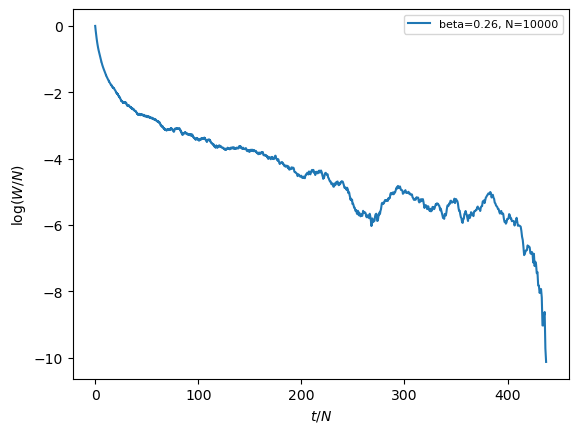

In [19]:
for beta in [0.26]:
    for N in [10000]:
        csv_path = f"../results/tmp/nb_star_DS_ER_{coup_type}_d{d}_N{N}.csv"
        df = pd.read_csv(csv_path)
        sub_df = df[(df['beta'] == beta) & (df['N'] == N)].sort_values('time')
        t_over_N = sub_df['time'].values / N
        log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
        plt.plot(t_over_N, log_W_over_N, label=f'beta={beta:.2f}, N={N}')

plt.xlabel(r'$t/N$')
plt.ylabel(r'$\log(W/N)$')
plt.legend(fontsize=8)
plt.show()